In [1]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv.zip", compression="zip")

In [2]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [4]:
df.shape

(2443651, 9)

In [5]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [ ]:
# Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

# 1. Frequency Tables:

# Generate a frequency table for the product category.
# Which are the top 5 most listed product categories?

# Answer: Top 5 categories are: Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body and Birthday Gifts              

In [19]:
frequency_table = df['category'].value_counts()
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [21]:
top10_frequency_table = df['category'].value_counts().head(10)
top10_frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [ ]:
# 2. Visualizations:

# Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, 
# do it for a subset of top categories.
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

# Answer: Sports & Outdoors represent 34,2% of all categories and is a clearly dominating category.

/var/folders/lw/p1gnqnq90vx9w4b97fnlh85r0000gn/T/ipykernel_42102/4035446556.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_frequency_table.values, y=top10_frequency_table.index, palette="Set3");


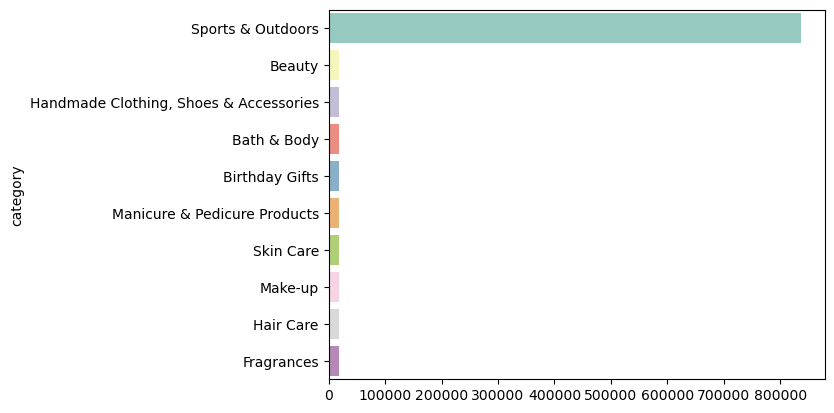

In [23]:
sns.barplot(x=top10_frequency_table.values, y=top10_frequency_table.index, palette="Set3");

<Axes: ylabel='count'>

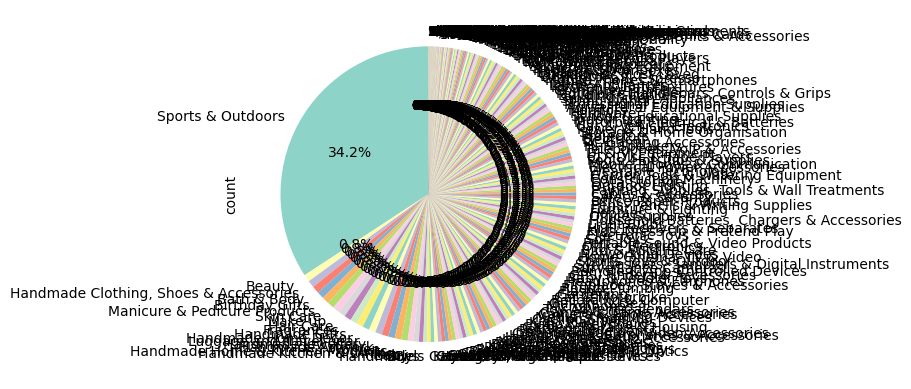

In [32]:
df['category'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

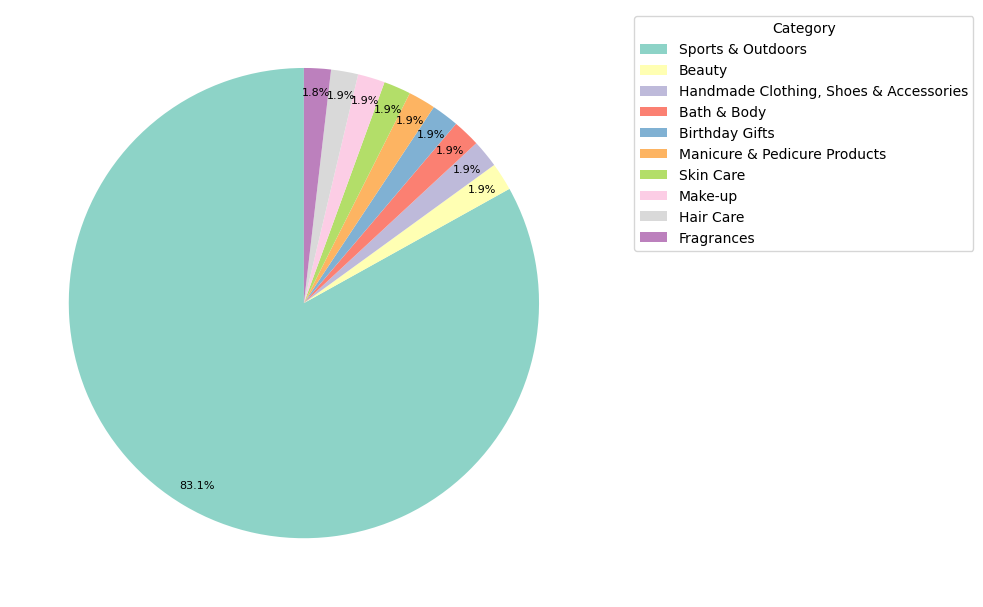

In [53]:
import matplotlib.pyplot as plt

counts = df['category'].value_counts().head(10)

plt.figure(figsize=(10, 10))

counts.plot.pie(
    autopct='%1.1f%%',
    labels=None,
    pctdistance=0.90,
    startangle=90,
    textprops={'fontsize': 8},
    colors=sns.color_palette("Set3")
)

plt.legend(
    counts.index,
    title="Category",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
# Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

# 1. Measures of Centrality:

# Calculate the mean, median, and mode for the price of products.
# What's the average price point of products listed? How does this compare with the most common price point (mode)?

# Answer: Average price point: 89.24
# Comparison with the mode: The average is far higher than the most common price (9.99) and the median (19.09), implying that 
# there are several expensive products that pull the average upward while most products are priced much lower.

In [81]:
mean_price = round(df['price'].mean(),2)
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24), 19.09, np.float64(9.99))

In [ ]:
# 2. Measures of Dispersion:

# Determine the variance, standard deviation, range, and interquartile range for product price.
# How varied are the product prices? Are there any indicators of a significant spread in prices?

# Answer: Product prices show a very high level of variability. The variance is 119,445.49 and the standard deviation is 345.61, 
# indicating that prices are widely dispersed around the mean. Prices range from €0.00 to €100,000.00, giving an overall range 
# of €100,000.00. However, the quartiles reveal that most products are priced much lower: 25% cost €9.99 or less, 
# 50% cost €19.09 or less, and 75% cost €45.99 or less. This suggests that a small number of extremely expensive products 
# are creating a large spread in the data and skewing the distribution. The standard deviation (345.61) being much larger 
# than the median (19.09) is another strong indication of these extreme values.

In [61]:
variance_price = round(df['price'].var(),2)
std_dev_price = round(df['price'].std(),2)
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.49,
 345.61,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

In [ ]:
# 3. Visualizations:

# Is there a specific price range where most products fall? Plot a histogram to visualize the 
# distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

# Answer: It's hard to read because there are a few outliers that are very far from the median. In this case, 
# it can be solved by displaying only 0.80 quantile to exclude these most extreme outliers.

# Are there products that are priced significantly higher than the rest? Use a box plot to showcase 
# the spread and potential outliers in product pricing.

# Answer: There are two products that are exreme outliers, priced at 77752.0 and 100000.0. However, there are also many outlier points 
# with a price up to €25,000.

<Axes: xlabel='price', ylabel='Count'>

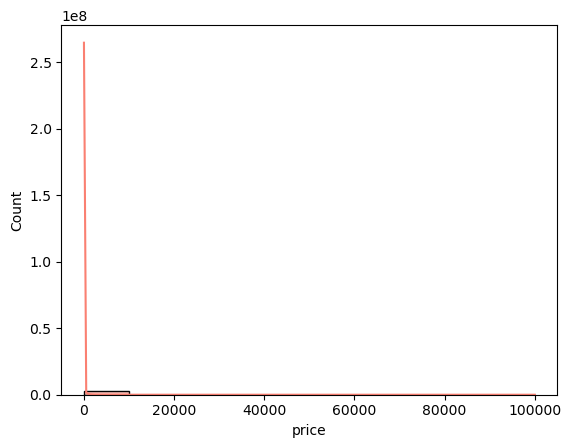

In [64]:
sns.histplot(df['price'], kde=True, bins=10, color="salmon")

<Axes: xlabel='price', ylabel='Count'>

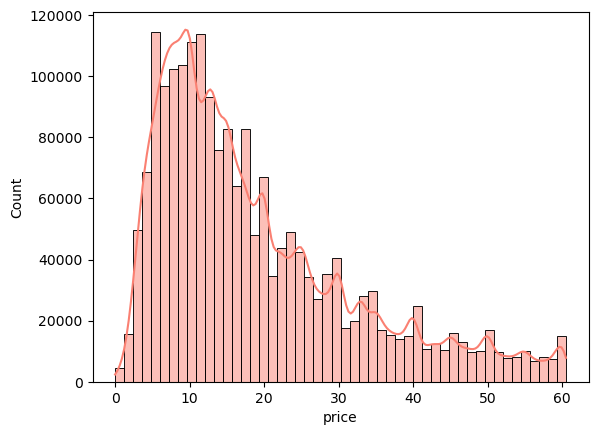

In [71]:
upper = df["price"].quantile(0.80)

sns.histplot(
    df[df["price"] <= upper]["price"],
    bins=50,
    kde=True,
    color="salmon"
)

<Axes: ylabel='price'>

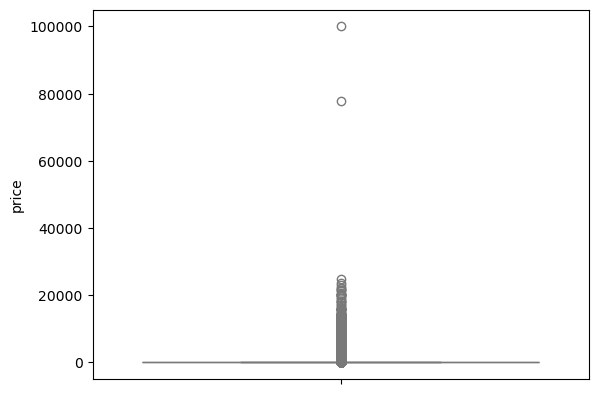

In [72]:
sns.boxplot(data = df['price'], color="lightblue")

In [73]:
df[df["price"] >= 70000]["price"].value_counts()

price
77752.0     1
100000.0    1
Name: count, dtype: int64

In [ ]:
# Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

# 1. Measures of Centrality:

# Calculate the mean, median, and mode for the rating of products.
# How do customers generally rate products? Is there a common trend?

# Answer: Customers generally give products high ratings. The average rating is 4.32, while the median rating is 4.40 
# and the most common rating (mode) is 4.50. Since the mean, median, and mode are all above 4 and relatively close to one another, 
# the ratings are consistently positive. This suggests that most rated products receive favorable customer feedback, 
# with 4.5 stars being the most common rating.

In [77]:
mean_rating = round(df['stars'].mean(),2)
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(2.15), 0.0, np.float64(0.0))

In [82]:
ratings_done = df[df["stars"] > 0]["stars"] #rating excluding 0 values when no reviews were found

mean_rating = ratings_done.mean()
median_rating = ratings_done.median()
mode_rating = ratings_done.mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(4.319160762226911), 4.4, np.float64(4.5))

0    4.7
1    4.7
2    4.7
3    4.7
4    4.6
Name: stars, dtype: float64

In [ ]:
# 2. Measures of Dispersion:

# Determine the variance, standard deviation, and interquartile range for product rating.
# Are the ratings consistent, or is there a wide variation in customer feedback?

# Answer: Based on these statistics, the ratings appear to be quite consistent. The average rating is 4.32, with a median of 4.40 
# and a mode of 4.50, indicating that most products receive ratings between 4 and 5 stars. 
# The low standard deviation (0.56) and narrow interquartile range (4.1–4.6) show that customer feedback 
# is relatively consistent, with only a small number of products receiving low ratings.

In [91]:
variance_rating = round(ratings_done.var(), 2)
std_dev_rating = round(ratings_done.std(), 2)
min_rating = ratings_done.min()
max_rating = ratings_done.max()
range_rating = max_rating - min_rating
quantiles_rating = ratings_done.quantile([0.25, 0.5, 0.75])

variance_rating, std_dev_rating, min_rating, max_rating, range_rating, quantiles_rating

(0.31,
 0.56,
 1.0,
 5.0,
 4.0,
 0.25    4.1
 0.50    4.4
 0.75    4.6
 Name: stars, dtype: float64)

In [ ]:
# 3. Shape of the Distribution:

# Calculate the skewness and kurtosis for the rating column.
# Are the ratings normally distributed, or do they lean towards higher or lower values?

# Answer: The ratings are not normally distributed. They are strongly skewed toward higher values, as indicated by 
# the negative skewness (-2.38). This shows that most products receive high ratings, while relatively few 
# receive low ratings. The high kurtosis (9.78) indicates a sharply peaked distribution with ratings heavily concentrated 
# around the upper end of the scale and only a small number of extreme low ratings.

In [93]:
skewness_rating = round(ratings_done.skew(),2)
kurtosis_rating = round(ratings_done.kurtosis(),2)

skewness_rating, kurtosis_rating

(np.float64(-2.38), np.float64(9.78))

In [ ]:
# 4. Visualizations:

# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

# Answer: The highest concentration of ratings is around 4.4–4.6 stars.
# There is a clear left tail, with relatively few ratings below 3 stars.
# The distribution is negatively skewed, which agrees with your skewness of -2.38.
# The histogram confirms that 4.5 stars is the most common rating.

<Axes: xlabel='stars', ylabel='Count'>

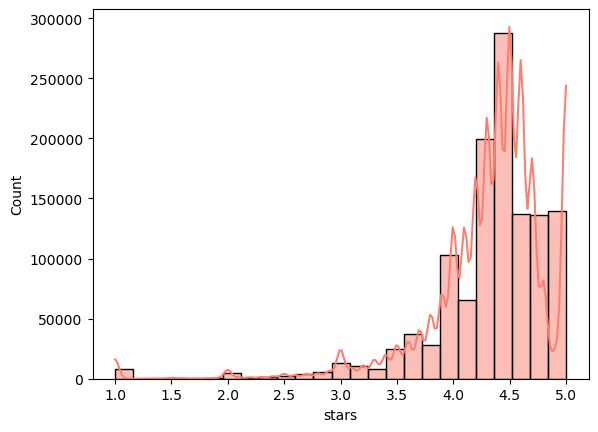

In [97]:
sns.histplot(ratings_done, kde=True, bins=25, color="salmon")

In [ ]:
# Business-Centric Summary:

#The analysis shows that Amazon UK's product catalog is concentrated in a few dominant categories, indicating strong competition. 
# Product prices vary widely due to a small number of premium-priced items, while most products are relatively affordable.

# Customer satisfaction is generally very high. Most rated products receive between 4 and 5 stars, with 4.5 stars
# being the most common rating.

# Business implications:
# - Use median prices rather than averages to understand typical market pricing.
# - Maintain high product quality, as customers expect ratings above 4 stars.
# - Since ratings are consistently high, sellers may gain a competitive advantage through pricing strategies, 
# product differentiation, and review volume rather than relying only on star ratings.